In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer # hàm nạp dataset mẫu về ung thư vú, có sẵn trong scikit-learn.
from sklearn.model_selection import train_test_split # hàm chia dữ liệu thành train và test.
from sklearn.linear_model import LogisticRegression # mô hình phân loại thứ nhất (Buổi 2 sẽ giải thích cách nó hoạt động).
from sklearn.tree import DecisionTreeClassifier # mô hình thứ hai, cây quyết định. Hôm nay dùng nó để minh họa overfitting.

In [ ]:
# Ô 2 — Nạp dữ liệu và xem nó là gì
data = load_breast_cancer(as_frame=True) # as_frame=True trả dữ liệu dạng DataFrame của pandas thay vì mảng NumPy

X, y = data.data, data.target # data.data là bảng feature, data.target là cột nhãn.
print(X.shape, y.shape)
print(list(data.target_names))
print(data.target_names) # ý nghĩa của nhãn. 0 = malignant (ác tính), 1 = benign (lành tính).
print(y.value_counts().to_dict()) # có 357 mẫu lành tính và 212 mẫu ác tính
# X.iloc[:2, :4]: xem 2 dòng đầu và 4 cột đầu. Mọi feature đều là số. Mô hình chỉ học được từ số, nên Buổi 3 mới phải học cách biến văn bản thành số.
X.iloc[:2,:4]

# Đặt câu hỏi kiểu Chặng 1: mỗi dòng là gì? Mỗi dòng là một khối u, 
# X mô tả hình dạng tế bào, y cho biết khối u đó lành hay ác.

(569, 30) (569,)
[np.str_('malignant'), np.str_('benign')]
['malignant' 'benign']
{1: 357, 0: 212}


,mean radius,mean texture,mean perimeter,mean area
0,17.99,10.38,122.8,1001.0
1,20.57,17.77,132.9,1326.0


In [15]:
# Ô 3 — Chia train và test

# train_test_split(X, y, ...): chia ngẫu nhiên cả X và y cùng lúc, nên mỗi dòng feature vẫn đi kèm đúng nhãn của nó
X_train, X_test, y_train, y_test = train_test_split(
  X,y, test_size=0.25, stratify=y, random_state=42)
# test_size=0.25: 25% làm test (143 mẫu), 75% làm train (426 mẫu).
# stratify=y: chia phân tầng, giữ tỷ lệ nhãn ở train và test giống nhau.
# random_state=42: cố định cách xáo trộn. Chạy lại bao nhiêu lần cũng ra đúng cách chia này, và người khác chạy cũng ra kết quả giống bạn. Con số 42 không có gì đặc biệt, chỉ là quy ước quen dùng.

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict()) 

(426, 30) (143, 30)
{1: 0.627, 0: 0.373}
{1: 0.629, 0: 0.371}


In [ ]:
# Ô 4 — Huấn luyện mô hình và dự đoán
model = LogisticRegression(max_iter=5000)
# tạo một mô hình chưa học gì. max_iter là số vòng tối đa để mô hình tìm công thức. Mặc định là 100, quá ít với dữ liệu này nên sẽ hiện cảnh báo ConvergenceWarning, vì vậy tăng lên 5000.
model.fit(X_train, y_train) # học. Sau dòng này, model đã chứa công thức rút ra từ 426 mẫu train.

print(model.predict(X_test[:5]))
print(y_test[:5].tolist())
# thay vì chỉ trả nhãn, trả xác suất cho từng lớp. Mỗi dòng có hai số cộng lại bằng 1: cột trái là xác suất ác tính, cột phải là xác suất lành tính. predict chỉ đơn giản chọn lớp có xác suất lớn hơn 0,5.
model.predict_proba(X_test[:5]).round(3)
# Câu sai thứ 5 có xác suất lành tính 0,801, tức mô hình sai mà vẫn khá tự tin. Một con số xác suất cao không có nghĩa là chắc chắn đúng.

[1 0 1 1 1]
[1, 0, 1, 1, 0]


array([[0.019, 0.981],
       [0.998, 0.002],
       [0.177, 0.823],
       [0.234, 0.766],
       [0.2  , 0.8  ]])

In [ ]:
# Ô 5 — Chấm điểm trên tập test
print(round(model.score(X_test, y_test),3)) # dự đoán toàn bộ tập test rồi tính accuracy (tỷ lệ đoán đúng). Kết quả 95,8%.

y_pred = model.predict(X_test)
print(round((y_pred == y_test).mean(),3))
# (y_pred == y_test): so từng cặp, ra một dãy True/False. .mean() là tỷ lệ True, giống cách đếm ở Chặng 1. Dòng này cho thấy score không có gì bí ẩn: nó chỉ đếm số câu đúng.

print((y_pred != y_test).sum(),len(y_test)) # (y_pred != y_test).sum(): mô hình sai 6 trên 143 mẫu.

0.958
0.958
6 143


In [ ]:
# Ô 6 — So điểm train và điểm test
print(round(model.score(X_train, y_train),3))
print(round(model.score(X_test, y_test),3))
# Chấm trên chính dữ liệu đã học (train) và trên dữ liệu chưa thấy (test).
# Hai điểm bằng nhau, nghĩa là mô hình không học thuộc lòng: nó làm bài mới tốt ngang bài đã luyện. Đây là dấu hiệu của một mô hình tốt.
# Quy tắc đọc: train cao hơn test rất nhiều là overfitting; cả hai cùng thấp là underfitting; cả hai cùng cao và gần nhau là tốt.

0.958
0.958


In [ ]:
# Ô 7 — Tận mắt thấy overfitting với cây quyết định
tree = DecisionTreeClassifier(random_state=42)
# DecisionTreeClassifier(random_state=42): không giới hạn độ sâu, nên cây cứ hỏi tiếp cho đến khi phân loại đúng 100% dữ liệu train.
tree.fit(X_train,y_train)
print(tree.score(X_train,y_train), round(tree.score(X_test,y_test),3))

print(tree.get_depth(), tree.get_n_leaves())

tree3 = DecisionTreeClassifier(max_depth=3,random_state=42)
# max_depth=3: giới hạn chỉ được hỏi 3 tầng. Cây buộc phải học quy luật chung thay vì nhớ từng mẫu. Train giảm xuống 0,977 nhưng test tăng lên 0,944.
tree3.fit(X_train,y_train)
print(round(tree3.score(X_train, y_train),3), round(tree3.score(X_test,y_test)))

1.0 0.923
7 18
0.977 1


In [ ]:
# Ô 8 — Thay đổi độ sâu, xem cả underfitting lẫn overfitting
rows = []
for d in range(1, 11):
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": d,
                 "train": round(t.score(X_train, y_train), 3),
                 "test": round(t.score(X_test, y_test), 3)})
result = pd.DataFrame(rows)
print(result.to_string(index=False))

# Độ sâu 1: chỉ hỏi một câu, cả train và test đều 0,923. Mô hình quá đơn giản: underfitting.
# Độ sâu 3–4: điểm test cao nhất (0,944). Đây là vùng vừa phải.
# Độ sâu từ 7 trở lên: train đạt 100%, nhưng test tụt về 0,923 và đứng yên. Đó là overfitting.

 max_depth  train  test
         1  0.923 0.923
         2  0.958 0.909
         3  0.977 0.944
         4  0.988 0.944
         5  0.995 0.937
         6  0.998 0.937
         7  1.000 0.923
         8  1.000 0.923
         9  1.000 0.923
        10  1.000 0.923


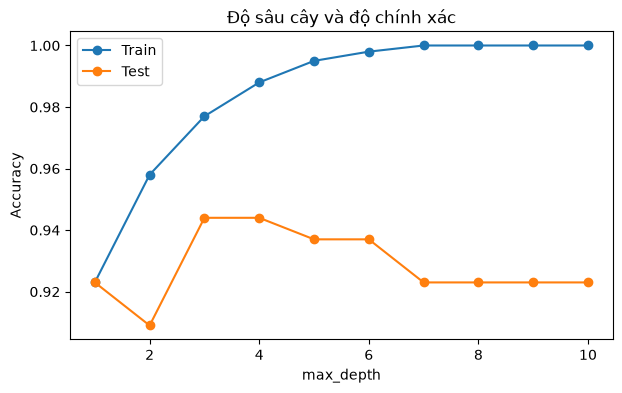

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(result["max_depth"], result["train"], marker="o", label="Train")
ax.plot(result["max_depth"], result["test"], marker="o", label="Test")
ax.set(title="Độ sâu cây và độ chính xác", xlabel="max_depth", ylabel="Accuracy")
ax.legend()
plt.show()

In [ ]:
# Ô 9 — Lỗi kinh điển: để đáp án lọt vào feature
X_leak = X.assign(target_copy=y)          # vô tình thêm cột nhãn vào X
# X.assign(target_copy=y): tạo bản sao của X có thêm một cột chứa đúng đáp án. Ngoài đời, lỗi này thường xảy ra khi bạn quên bỏ cột nhãn, hoặc giữ một cột “chứa ngầm” đáp án.
Xtr, Xte, ytr, yte = train_test_split(X_leak, y, test_size=0.25,
                                      stratify=y, random_state=42)
t = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
print(t.score(Xte, yte), t.get_depth())   # 1.0 1

1.0 1


In [26]:
# Ô 10 — Liên hệ M3: X và y của dự án là gì
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))
from src.clean import load_events, clean_events

ev = clean_events(load_events(Path("..") / "data" / "raw" / "evtx_data.csv"))
print(ev.shape)                               # (4633, 16)
y_m3 = ev["EVTX_Tactic"]
print(y_m3.value_counts().head(3).to_dict())
# {'Lateral Movement': 1288, 'Privilege Escalation': 1088, 'Execution': 533}

(4633, 16)
{'Lateral Movement': 1288, 'Privilege Escalation': 1088, 'Execution': 533}
